# Envelope/fusion proxy

This proposed score combined possible disulfide pairs with sequence patterns intended to flag viral envelope or fusion proteins. The audit fixed the score and tested it on newly selected viral proteins after excluding proteins and sequences used earlier.

## Reproduction scope

The original sequence-based composite rule and exact confirmation samples are replayed.

Saved outputs replay archived sample-level records. The opt-in workflow above generates new predictions and axis analyses from the pinned original sources.

The compact package keeps the saved main-axis curves and historical decisions. Full original source displays and large candidate galleries are regenerated by running the notebook. The next cell verifies and expands the bundled small artifacts offline; large references/MSAs/model weights are downloaded only by the explicit full-workflow switch.


In [41]:
from pathlib import Path
import json,hashlib,importlib.util,sys,io
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from IPython.display import display,Image
import matplotlib
matplotlib.use('Agg')
from matplotlib import pyplot as plt
root=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'ESM_INPUTS.json').is_file()),None)
assert root is not None,'Extract the full ESMFold2 bundle and open this notebook inside it.'
sys.path.insert(0,str(root))
from bootstrap import ensure_assets
ensure_assets(root)
manifest=json.loads((root/'ESM_INPUTS.json').read_text());P=root/'source/esmfold2';A=P/'reconstruction/prior_axes'
def checked(p):
    p=Path(p);k=str(p.relative_to(root));assert hashlib.sha256(p.read_bytes()).hexdigest()==manifest[k]['sha256'],k
    return p
def read(p):return pd.read_csv(checked(p),low_memory=False)
def module(p):
    p=checked(p);sys.path.insert(0,str(p.parent));spec=importlib.util.spec_from_file_location('replay_'+p.stem,p);m=importlib.util.module_from_spec(spec);spec.loader.exec_module(m);return m
def equal_curve(got,path,keys,columns):
    old=read(path)
    if 'selection' in old:old=old[old.selection=='best_by_ptm']
    a=got.set_index(keys).sort_index();b=old.set_index(keys).sort_index()
    assert a.index.tolist()==b.index.tolist(),'Group identities changed'
    for c in columns:np.testing.assert_allclose(a[c],b[c],rtol=1e-9,atol=1e-10,equal_nan=True,err_msg=c)
    print('Matched original group identities and statistics:',path.name)
def plot_rows(df,level,metric='ca_lddt',label='Retained evaluation'):
    # Replay diagnostic intervals: 2,000 resamples of target records, seed 7.
    # These are not new inference or an additional independent cohort.
    rng=np.random.default_rng(7);rows=[]
    for lev,g in df.groupby(level,observed=True):
        v=g[metric].dropna().to_numpy(float)
        if not len(v):continue
        b=np.array([rng.choice(v,len(v),replace=True).mean() for _ in range(2000)])
        rows.append({'level':lev,'n':len(v),'mean':v.mean(),'lo':np.quantile(b,.025),'hi':np.quantile(b,.975)})
    t=pd.DataFrame(rows);display(t)
    fig,ax=plt.subplots(figsize=(7,4),layout='constrained');ax.errorbar(range(len(t)),t['mean'],yerr=np.vstack([t['mean']-t.lo,t.hi-t['mean']]),marker='o',capsize=3)
    ax.set_xticks(range(len(t)),t.level.astype(str));ax.set(xlabel=level,ylabel=metric,title=label);ax.spines[['top','right']].set_visible(False)
    b=io.BytesIO();fig.savefig(b,format='png',dpi=120);plt.close(fig);display(Image(data=b.getvalue()));return t


In [2]:

# Original files recovered read-only from exxact05; validation is separate from old bundle hashes.
from IPython.display import HTML, Markdown
import html, tempfile
ORIGINAL_MANIFEST=json.loads((root/'REMOTE_FILE_MANIFEST.json').read_text())
ORIGINAL_HASHES={x['relative_destination']:x for x in ORIGINAL_MANIFEST['files']}
R=root/'original_runs'
def original_checked(p):
    p=Path(p);rel=str(p.relative_to(root));assert rel in ORIGINAL_HASHES,rel
    assert hashlib.sha256(p.read_bytes()).hexdigest()==ORIGINAL_HASHES[rel]['sha256'],rel
    return p
def original_read(p):return pd.read_csv(original_checked(p),low_memory=False)
def original_module(p):
    p=original_checked(p);sys.path.insert(0,str(p.parent))
    name='original_'+hashlib.sha256(str(p).encode()).hexdigest()[:12]
    spec=importlib.util.spec_from_file_location(name,p);mod=importlib.util.module_from_spec(spec);sys.modules[name]=mod;spec.loader.exec_module(mod);return mod

def original_sources(run_names, notebook_name):
    # Show the actual original acquisition, processing, inference and decision programs, not a replacement recipe.
    coverage=json.loads((root/'CANDIDATE_COVERAGE.json').read_text())
    selected=[x for x in coverage['files'] if notebook_name in x['notebooks']]
    display(pd.DataFrame([{'file':x['relative_destination'],'original_remote_path':x['remote_path'],'bytes':x['bytes'],'sha256':x['sha256']} for x in selected]))
    for item in selected:
        p=original_checked(root/item['relative_destination'])
        if p.suffix in {'.py','.md'} or p.name in {'commands_run.json','axis_ledger.json','spectra_loop_state.json'} or 'manifest' in p.name or 'definitions' in p.name:
            text=p.read_text()
            display(HTML('<details><summary>'+html.escape(item['relative_destination'])+'</summary><pre style="white-space:pre-wrap">'+html.escape(text)+'</pre></details>'))
    print('Original source files verified:',len(selected))

def archive_curve_gallery(df,label):
    level=next((c for c in ['axis_level','stress_rank','level','external_axis_level','charge_level','acidic_window_level','cys_level','viral_disulfide_score','envelope_fusion_score','surface_lowhelical_score','quartile'] if c in df),None)
    metric=next((c for c in ['ca_lddt_mean','target_ca_lddt_mean','ca_lddt'] if c in df),None)
    axis=next((c for c in ['axis_id','axis_name','axis','feature'] if c in df),None)
    if level is None or metric is None:return
    work=df.copy();work['_axis']=work[axis].astype(str) if axis else label
    axes=work['_axis'].unique()
    # Each candidate gets a panel; original source/split/selection curves are kept as separate lines.
    for start in range(0,len(axes),12):
        names=axes[start:start+12];fig,axs=plt.subplots((len(names)+2)//3,3,figsize=(15,3.6*((len(names)+2)//3)),squeeze=False,layout='constrained')
        for ax,name in zip(axs.flat,names):
            sub=work[work['_axis']==name]
            linecols=[c for c in ['subset','source','inference_setting','selection','selection_policy','direction','level_schema','n_levels_requested'] if c in sub]
            grouper=sub.groupby(linecols,dropna=False,sort=False) if linecols else [('original',sub)]
            for key,part in grouper:
                part=part.sort_values(level);ax.plot(part[level],part[metric],marker='.',linewidth=.8,label=str(key))
            ax.set(title=str(name),xlabel=level,ylabel=metric);ax.tick_params(labelsize=7);ax.title.set_fontsize(8)
            if linecols:ax.legend(fontsize=4,loc='best')
        for ax in list(axs.flat)[len(names):]:ax.axis('off')
        buf=io.BytesIO();fig.savefig(buf,format='png',dpi=100);plt.close(fig);display(Image(data=buf.getvalue()))

def original_candidate_tables(notebook_name):
    inventory=json.loads((root/'CANDIDATE_COVERAGE.json').read_text())
    selected=[x for x in inventory['files'] if notebook_name in x['notebooks'] and x.get('screen_or_curve')]
    display(pd.DataFrame([{'source':x['relative_destination'],'screen_rows':x['rows'],'candidate_names':x.get('candidate_count',0)} for x in selected]))
    for item in selected:
        table=original_read(root/item['relative_destination'])
        # All rows, including negatives and discarded directions, remain inspectable in each notebook.
        display(HTML('<details><summary>'+html.escape(item['relative_destination'])+' — '+str(len(table))+' original rows</summary>'+table.to_html(index=False,max_rows=None,max_cols=None)+'</details>'))
        if 'curve' in Path(item['relative_destination']).name:archive_curve_gallery(table,Path(item['relative_destination']).name)
    print('Complete original candidate screens/curves displayed:',len(selected))


## Run the original workflow

See [ENVIRONMENTS.txt](../ENVIRONMENTS.txt) for the separate notebook and model environments. Set `RUN_ORIGINAL_WORKFLOW=True` below, or use the shared runner’s `--original-workflow` flag. This executes acquisition, feature reconstruction, current-model inference and this axis’s original analyses. All 12 notebooks share one workspace; each axis writes separate analysis outputs.

The original cohorts, metadata, reference fit and frozen memberships remain fixed. Rebuilt feature values and newly scored outcomes feed the rerun. Missing or stale inputs stop the chain. Model failures/nonfinite reference scores are reported explicitly using the original finite-row rules.

The current public implementation uses pinned original source weights. The completed comparison verified 2,658 tensor keys/shapes only; prediction equivalence was not established. Historical agent decisions below remain unchanged.

Validation: [all12 axis dispatches](../WORKFLOW_VALIDATION.json), [input/result propagation checks](../WORKFLOW_GUARD_VALIDATION.json), and [original curve comparison](../CURVE_REPLAY_VALIDATION.json). These use retained original data/results; the full new-model run is opt-in and has not been executed here.


In [42]:
import importlib, subprocess, os
sys.path.insert(0,str(root))
import acquisition, current_implementation, original_workflow
acquisition=importlib.reload(acquisition)
current_implementation=importlib.reload(current_implementation)
original_workflow=importlib.reload(original_workflow)
AXIS_NUMBER = 11
# Set True here, or run execute_notebook.py --original-workflow from ENVIRONMENTS.txt.
RUN_ORIGINAL_WORKFLOW = os.environ.get('SPECTRA_RUN_ORIGINAL_WORKFLOW','0') == '1'
# Shared across all12 notebooks: references, model weights, environment and per-panel results.
REPRODUCTION_DIR = Path(os.environ.get('SPECTRA_ESMFOLD2_WORKSPACE',str(root/'reproduction'/'transformers-5.22.2'))).resolve()
INFERENCE_BACKEND = 'current'
# Optional stage switches allow explicit resume; the master switch activates the entire chain.
RUN_INFERENCE_SETUP = RUN_ORIGINAL_WORKFLOW
RUN_DOWNLOADS = RUN_ORIGINAL_WORKFLOW
RUN_REBUILD_INPUTS = RUN_ORIGINAL_WORKFLOW
RUN_MODEL_DOWNLOAD = RUN_ORIGINAL_WORKFLOW
RUN_CONVERT_MODEL = RUN_ORIGINAL_WORKFLOW
RUN_INFERENCE = RUN_ORIGINAL_WORKFLOW
RUN_RERUN_SUMMARY = RUN_ORIGINAL_WORKFLOW
INFERENCE_PYTHON = str(REPRODUCTION_DIR/'environment-current'/'bin/python')
if RUN_ORIGINAL_WORKFLOW:
    # Install the notebook environment before starting this kernel; do not replace live NumPy/pandas.
    import importlib.metadata as metadata
    required={'numpy':'2.1.2','pandas':'2.3.1'}
    mismatch={k:metadata.version(k) for k,v in required.items() if metadata.version(k)!=v}
    if mismatch:raise RuntimeError('Use the separate notebook environment described in ENVIRONMENTS.txt; incompatible live versions: '+str(mismatch))
if RUN_INFERENCE_SETUP:
    INFERENCE_PYTHON=current_implementation.install_environment(REPRODUCTION_DIR)
plan=acquisition.download_plan(AXIS_NUMBER,REPRODUCTION_DIR)
print('Original panels:',acquisition.panels_for(AXIS_NUMBER))
print('Planned exact source files:',len(plan),'| full workflow enabled:',RUN_ORIGINAL_WORKFLOW)
print('Shared workspace:',REPRODUCTION_DIR)
print('Current package:',current_implementation.PINS['transformers'],'| Torch:',current_implementation.PINS['torch'])
display(pd.DataFrame(plan)[['kind','url','destination']].head(12))
assert all(item.get('sha256') or item.get('git_blob_sha1') for item in plan)


Original panels: ['viral36', 'envelope38']
Planned exact source files: 66 | full workflow enabled: False
Shared workspace: <package>/reproduction/transformers-5.22.2
Current package: 5.22.2 | Torch: 2.6.0


kind                                       url  \
0   experimental_reference  https://files.rcsb.org/download/30RA.cif   
1   experimental_reference  https://files.rcsb.org/download/9UYS.cif   
2   experimental_reference  https://files.rcsb.org/download/9QEB.pdb   
3   experimental_reference  https://files.rcsb.org/download/9X4G.pdb   
4   experimental_reference  https://files.rcsb.org/download/9TAW.pdb   
5   experimental_reference  https://files.rcsb.org/download/9LFA.cif   
6   experimental_reference  https://files.rcsb.org/download/28OP.pdb   
7   experimental_reference  https://files.rcsb.org/download/9SZO.cif   
8   experimental_reference  https://files.rcsb.org/download/9H51.cif   
9   experimental_reference  https://files.rcsb.org/download/9X40.cif   
10  experimental_reference  https://files.rcsb.org/download/9ZRR.cif   
11  experimental_reference  https://files.rcsb.org/download/9OQD.pdb   

                                          destination  
<historical local execution path omitted><historical local execution path omitted><historical local execution path omitted><historical local execution path omitted><historical local execution path omitted><historical local execution path omitted><historical local execution path omitted><historical local execution path omitted><historical local execution path omitted><historical local execution path omitted><historical local execution path omitted><historical local execution path omitted>

In [43]:
# Downloaded reference coordinates feed the original accuracy evaluator.
# Recomputed features are materialized in panels/<panel>/features.csv and bound by a hash receipt.
if RUN_DOWNLOADS:
    receipts=acquisition.fetch_references(AXIS_NUMBER,REPRODUCTION_DIR)
    print('Exact source files verified:',len(receipts))
else:
    print('Downloads off; archived analysis replay follows. Enable RUN_ORIGINAL_WORKFLOW for the full chain.')
if RUN_REBUILD_INPUTS:
    rebuilt=acquisition.reconstruct_features(AXIS_NUMBER,REPRODUCTION_DIR)
    display(pd.DataFrame(rebuilt['panels']).T)
else:
    print('Fresh feature reconstruction is off. Frozen cohort IDs and fitted split memberships are preserved when rebuilding.')


Downloads off; archived analysis replay follows. Enable RUN_ORIGINAL_WORKFLOW for the full chain.
Fresh feature reconstruction is off. Frozen cohort IDs and fitted split memberships are preserved when rebuilding.


In [44]:
# Model inference is a separate process in environment-current; no old private source is required.
if RUN_MODEL_DOWNLOAD:
    model_directories=acquisition.download_model(REPRODUCTION_DIR,backend=INFERENCE_BACKEND)
    print('Pinned original sources:',model_directories)
if RUN_CONVERT_MODEL:
    conversion=current_implementation.convert_in_environment(REPRODUCTION_DIR,python=INFERENCE_PYTHON)
    print('This conversion run:',conversion['tensors'],'tensors; saved values exact:',conversion['saved_tensor_values_exact'])
if RUN_INFERENCE:
    results=acquisition.run_inference(AXIS_NUMBER,REPRODUCTION_DIR,python=INFERENCE_PYTHON,backend=INFERENCE_BACKEND)
    display(pd.DataFrame(results).T)
if RUN_RERUN_SUMMARY:
    rerun=acquisition.summarize_rerun(AXIS_NUMBER,REPRODUCTION_DIR)
    print('Axis-specific original analyses:',rerun['status'])
    display(pd.DataFrame([{'artifact':k,'path':v} for k,v in rerun['artifacts'].items()]))
    for name,path in rerun['artifacts'].items():
        if name.endswith('.csv') and any(term in name for term in ['curve','screen','effects','summary','candidate']):
            table=pd.read_csv(path)
            display(table)
            archive_curve_gallery(table,'New evaluations: '+name)
if not any([RUN_MODEL_DOWNLOAD,RUN_CONVERT_MODEL,RUN_INFERENCE,RUN_RERUN_SUMMARY]):
    print('Fresh model stages off. Below: original archived measurements, curves and agent decisions.')
comparison=json.loads((root/'IMPLEMENTATION_COMPARISON.json').read_text())
display(comparison)


Fresh model stages off. Below: original archived measurements, curves and agent decisions.


## Original download → processing → curves → determination

The recovered original programs and recorded command histories below document the CAMEO/RCSB downloads, feature construction, target selection, ESMFold2 evaluation and the agent's decisions. All 406 recovered files are checked against their remote SHA-256 hashes. The original reports and ledgers retain both accepted and discarded candidates.

The numerical cells replay the archived individual/sample measurements and original processing functions. Network downloads and GPU inference are not launched on opening this notebook. Raw alignment/coordinate/model files were intentionally excluded from this approved transfer; their original acquisition code, source addresses, remote paths and manifests are retained below. That is a storage boundary, not evidence that the original run omitted acquisition. Each group also includes the complete original candidate-screen tables, with preserved curve points and curve galleries, so rejected candidates are visible.


In [6]:
original_sources(['esmfold2_envelope_fusion_axis_confirmation_20260602'], 'notebooks/test-11.ipynb')


Original source files verified: 28


In [7]:
D=A/'10_11_envelope_surface';m=module(D/'scripts'/'summarize_envelope_fusion_confirmation.py')
f=read(D/'spectra_ready_dataset'/'envelope_fusion_confirmation_candidate_features.csv');r=read(D/'target_model_results.envelope_fusion_confirmation.scaled_samples.csv')
assert f.target_id.is_unique
np.testing.assert_array_equal(f.sequence.str.len(),f.seq_len)
print('Exact targets:',len(f),'prediction sample rows:',len(r));display(f[['target_id','sequence','envelope_fusion_score']].head())

Exact targets: 38 prediction sample rows: 190


,target_id,sequence,envelope_fusion_score
0,8X5P_1_A,GITQQVLAENQKLIANKFNQALGAMQTGFTTSNLAFSKVQDAVNAN...,0
1,9COF_1_A,MGLKVNVSAIFMAVLLTLQTPTGQIHWGNLSKIGVVGIGSASYKVM...,0
2,8ZX7_1_A,ANAFNNALDAIQEGFDATNSALVKIQAVVNANAEALNNLLQGGGGG...,0
3,8X5O_1_A,GITQQVLAENQKLIANKFNQALGAMQTGFTTSNLAFSKVQDAVNAN...,0
4,8UA8_4_D,IENDCIFEVKHEGKVTGYACLVGDKVMKPAHVKGVIDNADLAKLAF...,0


In [8]:
b=module(D/'scripts/build_surface_lowhelical_confirmation_panel.py');e=module(D/'scripts/build_envelope_fusion_confirmation_panel.py')
for col,fn in [('disulfide_capacity_per100',b.disulfide_capacity_per100),('tm_helix_proxy_calc',b.tm_proxy),('nglyc_motif_count',b.nglyc_count)]:
    np.testing.assert_allclose(f.sequence.map(fn),f[col],atol=1e-10)
np.testing.assert_array_equal(f.apply(e.level,axis=1),f.envelope_fusion_score)
print('Sequence-feature/level checks completed.')

Sequence-feature/level checks completed.


Matched original group identities and statistics: envelope_fusion_confirmation_level_curves.csv


,level,n,mean,lo,hi
0,0,13,0.667221,0.572904,0.758536
1,1,10,0.379991,0.268111,0.526900
2,2,15,0.527411,0.468158,0.585907


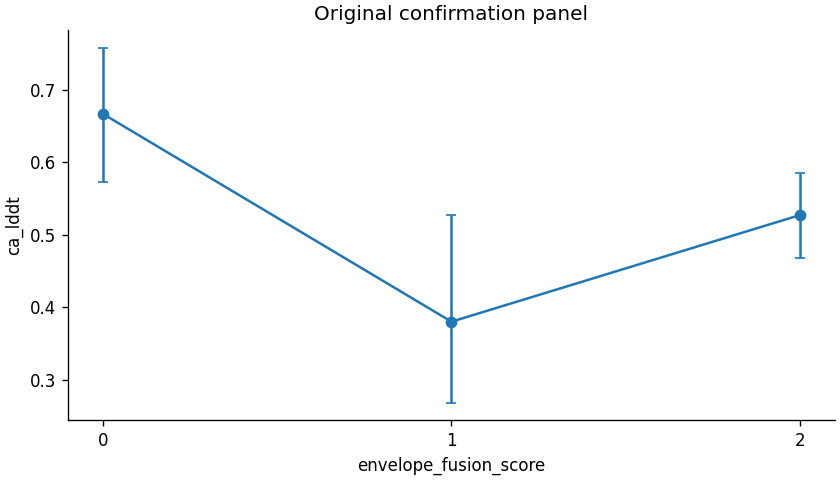

{
  "selection": "best_by_ptm",
  "n_panel": 38,
  "n_finite": 38,
  "n_top": 15,
  "n_lower": 23,
  "top_minus_lower_ca_lddt": -0.01492724340941931,
  "top_minus_level0_ca_lddt": -0.13981016175677152,
  "top_minus_lower_gdt_ts": -0.25455489170753304,
  "top_minus_lower_ca_rmsd_median": 7.236018026517197,
  "top_minus_lower_baseline_ca_lddt": -0.009707865890422454,
  "spearman_score_vs_ca_lddt": {
    "rho": -0.28085976048678596,
    "p": 0.0876229081088158
  },
  "bootstrap_top_minus_lower_ca_lddt": {
    "n_top": 15,
    "n_lower": 23,
    "mean": -0.016246517544349554,
    "ci_low": -0.12795381176280418,
    "ci_high": 0.09657926349798024
  },
  "adjusted_length_resolution_method": {
    "n": 38,
    "coef": 0.142404046166131,
    "se": 0.06762785432125504,
    "t": 2.1057010841962236,
    "controls": [
      "log_len",
      "resolution",
      "method_em"
    ]
  },
  "adjusted_length_only": {
    "n": 38,
    "coef": 0.16468230817551993,
    "se": 0.07484423254882396,
    "t": 2.

In [9]:
curve,effect,d=m.summarize_selection(f,r,'best_by_ptm')
equal_curve(curve,D/'analysis_outputs'/'envelope_fusion_confirmation_level_curves.csv',['envelope_fusion_score'],['n','ca_lddt_mean'])
plot_rows(d,'envelope_fusion_score',label='Original confirmation panel')
print(json.dumps(effect,indent=2))

## Remaining inputs

- The complete original predicted and experimental coordinate sets are outside this local transfer. These notebooks use archived per-target/per-sample metrics, not fresh inference.

Plotted mean intervals, where shown, are new replay diagnostics using 2,000 target resamples (seed 7). Original contrast intervals and control models are calculated by the supplied historical scripts where available. These checks do not constitute a new experiment.

## Recorded conclusion

The frozen envelope/fusion score failed confirmation.

Reproduction limitations are listed above. Original reported results remain separate from the recomputed outputs.

## Complete original candidate screens and curves

These are the full archived screen tables, including negative, discarded, weak and unresolved candidates. The recorded agent decisions are in the original ledgers/reports above. Candidate names recur across sources, directions, selection policies and stages; rows are not independent discoveries. Curves in this section use the original stored group statistics. Main-axis cells above separately recompute their statistics from individual records.

In [10]:
original_candidate_tables('notebooks/test-11.ipynb')

Complete original candidate screens/curves displayed: 3
